# سینمود  هوش مصنوعی سطح ۳  تشخیص حال از چهره 

In [4]:
import json
import random
from pathlib import Path
from collections import deque

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import (
    BatchNormalization, Conv2D, Dense, Dropout, Flatten, Input,
    MaxPooling2D, RandomFlip, RandomRotation, RandomZoom,
)

CSV_PATH = Path("E:/file/aio/tabestan/cinemood-mood/data/raw/fer2013.csv")
MODEL_PATH = Path("E:/file/aio/tabestan/cinemood-mood/notebook/cinemood.keras")
FACES_DIR = Path("E:/file/aio/tabestan/cinemood-mood/notebook/faces")         
SEED, BATCH, EPOCHS = 42, 64, 30


MOODS = ["angry", "happy", "neutral", "sad", "surprise"]
FER_NAMES = {0: "angry", 3: "happy", 4: "sad", 5: "surprise", 6: "neutral"}   # disgust و fear حذف می‌شوند

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## ۱) دیتاست: فقط ۵ حال قرارداد

mood
happy       8989
neutral     6198
sad         6077
angry       4953
surprise    4002
Name: count, dtype: int64


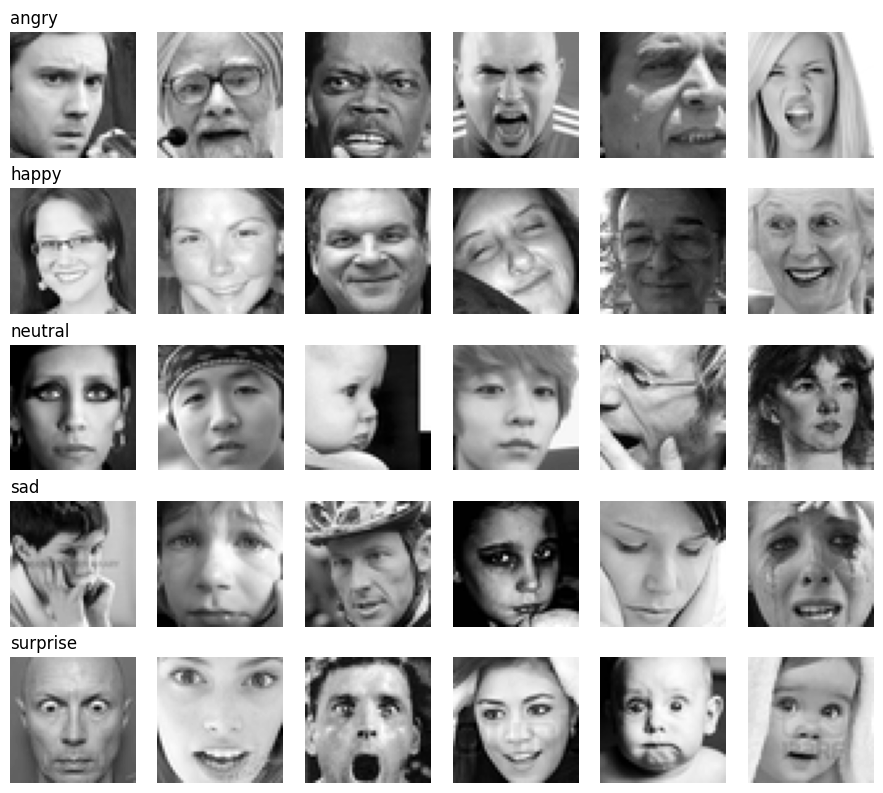

In [2]:
df = pd.read_csv(CSV_PATH)
df = df[df["emotion"].isin(FER_NAMES)].copy()
df["mood"] = df["emotion"].map(FER_NAMES)
print(df["mood"].value_counts())

X = np.stack([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in df["pixels"]])
X = X.astype("float32")[..., np.newaxis] / 255.0
y = df["mood"].map(MOODS.index).values

# چند نمونه از هر حال
fig, axes = plt.subplots(5, 6, figsize=(9, 8))
for row, mood in enumerate(MOODS):
    for col, img in enumerate(X[y == row][:6]):
        axes[row, col].imshow(img[..., 0], cmap="gray"); axes[row, col].axis("off")
    axes[row, 0].set_title(mood, loc="left")
plt.tight_layout(); plt.show()

## ۲) تقسیم داده: آموزش ۸۰٪ · اعتبارسنجی ۱۰٪ · تست ۱۰٪

In [3]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)
print(len(X_train), len(X_val), len(X_test))

24175 3022 3022


## ۳) مدل CNN  آموزش

In [12]:
model = Sequential([
    Input((48, 48, 1)),
    RandomFlip("horizontal"), RandomRotation(0.08), RandomZoom(0.08),

    Conv2D(32, 3, padding="same", activation="relu"), BatchNormalization(),
    Conv2D(32, 3, padding="same", activation="relu"), MaxPooling2D(), Dropout(0.25),

    Conv2D(64, 3, padding="same", activation="relu"), BatchNormalization(),
    Conv2D(64, 3, padding="same", activation="relu"), MaxPooling2D(), Dropout(0.25),

    Conv2D(128, 3, padding="same", activation="relu"), BatchNormalization(),
    MaxPooling2D(), Dropout(0.30),

    Flatten(), Dense(256, activation="relu"), BatchNormalization(), Dropout(0.50),
    Dense(len(MOODS), activation="softmax"),
])
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history = model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH, shuffle=True,

    callbacks=[
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
        ModelCheckpoint(str(MODEL_PATH), monitor="val_loss", save_best_only=True),
    ],
)


model = tf.keras.models.load_model(MODEL_PATH)

Epoch 1/30
378/378 [==============================] - 147s 380ms/step - loss: 1.7717 - accuracy: 0.3129 - val_loss: 2.3217 - val_accuracy: 0.2952 - lr: 0.0010
Epoch 2/30
378/378 [==============================] - 144s 380ms/step - loss: 1.3929 - accuracy: 0.4239 - val_loss: 1.2619 - val_accuracy: 0.4868 - lr: 0.0010
Epoch 3/30
378/378 [==============================] - 144s 381ms/step - loss: 1.2367 - accuracy: 0.4919 - val_loss: 1.5557 - val_accuracy: 0.4203 - lr: 0.0010
Epoch 4/30
378/378 [==============================] - 143s 378ms/step - loss: 1.1942 - accuracy: 0.5153 - val_loss: 1.1422 - val_accuracy: 0.5496 - lr: 0.0010
Epoch 5/30
378/378 [==============================] - 160s 422ms/step - loss: 1.1057 - accuracy: 0.5523 - val_loss: 1.2997 - val_accuracy: 0.4931 - lr: 0.0010
Epoch 6/30
378/378 [==============================] - 175s 462ms/step - loss: 1.0648 - accuracy: 0.5755 - val_loss: 1.0013 - val_accuracy: 0.6138 - lr: 0.0010
Epoch 7/30
378/378 [==========================

آپلود مدل و استفاده از ان

In [15]:
model = load_model("E:/file/aio/tabestan/cinemood-mood/notebook/cinemood.keras")

## ۴) نمودار accuracy و loss در طول آموزش

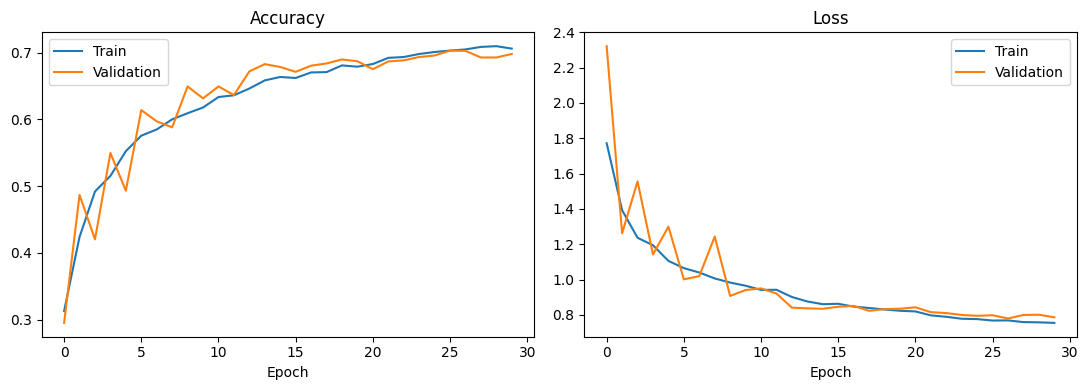

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in ((ax1, "accuracy"), (ax2, "loss")):
    ax.plot(history.history[name], label="Train")
    ax.plot(history.history["val_" + name], label="Validation")
    ax.set_title(name.capitalize()); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

## ۵) ارزیابی روی داده‌ی تست

Test Accuracy: 71.01%

              precision    recall  f1-score   support

       angry     0.6319    0.5988    0.6149       496
       happy     0.8643    0.8498    0.8570       899
     neutral     0.5942    0.6661    0.6281       620
         sad     0.5987    0.5898    0.5942       607
    surprise     0.8373    0.7850    0.8103       400

    accuracy                         0.7101      3022
   macro avg     0.7053    0.6979    0.7009      3022
weighted avg     0.7138    0.7101    0.7113      3022



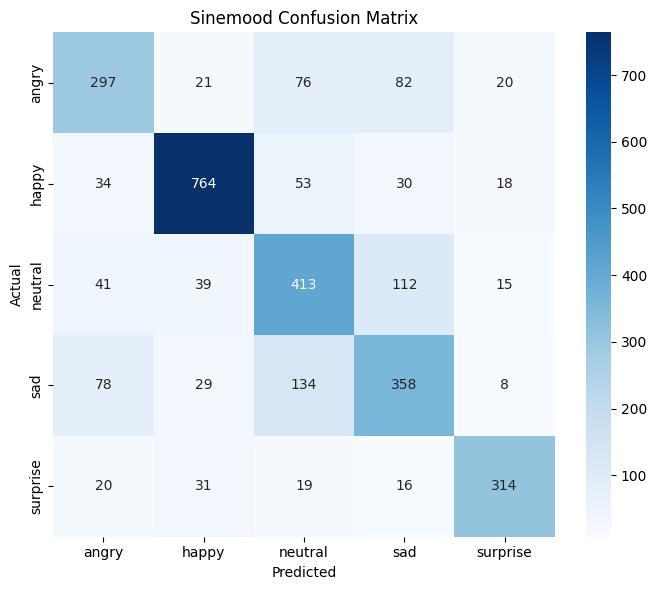

In [16]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc * 100:.2f}%\n")

y_pred = np.argmax(model.predict(X_test, batch_size=BATCH, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=MOODS, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=MOODS, yticklabels=MOODS)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Sinemood Confusion Matrix")
plt.tight_layout(); plt.show()

## ۶) اجرا روی 5 حالت از یک چهره 

face1.jpg {"mood": "neutral", "confidence": 0.76}
face2.jpg {"mood": "surprise", "confidence": 0.95}
face3.jpg {"mood": "happy", "confidence": 0.98}
face4.jpg {"mood": "angry", "confidence": 0.59}
face5.jpg {"mood": "sad", "confidence": 0.89}


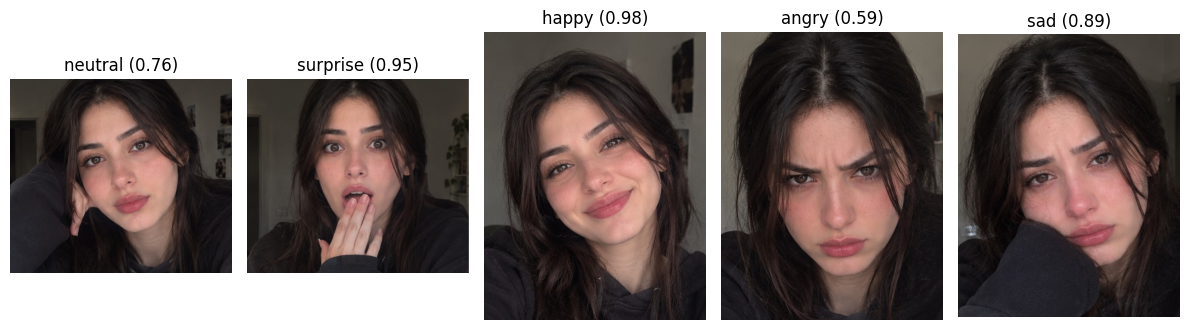

In [17]:
detector = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")


def predict_mood(path):
    
    image = ImageOps.exif_transpose(Image.open(path)).convert("L")
    faces = detector.detectMultiScale(np.asarray(image, dtype=np.uint8), 1.1, 5, minSize=(40, 40))
    if len(faces):
        x, y, w, h = (int(v) for v in max(faces, key=lambda b: b[2] * b[3]))
        image = image.crop((x, y, x + w, y + h))
    x = np.asarray(image.resize((48, 48), Image.LANCZOS), dtype=np.float32)[None, ..., None] / 255.0
    probs = model.predict(x, verbose=0)[0]
    best = int(np.argmax(probs))
    return {"mood": MOODS[best], "confidence": round(float(probs[best]), 2)}


fig, axes = plt.subplots(1, 5, figsize=(12, 4))
for i, ax in enumerate(axes, start=1):
    path = FACES_DIR / f"face{i}.jpg"
    if not path.exists():
        raise FileNotFoundError(f"عکس پیدا نشد: {path.resolve()}")
    result = predict_mood(path)
    print(path.name, json.dumps(result, ensure_ascii=False))
    ax.imshow(Image.open(path)); ax.set_title(f"{result['mood']} ({result['confidence']})"); ax.axis("off")
plt.tight_layout(); plt.show()

## تشخیص با وب کم و به صورت زنده

In [18]:
MODEL_PATH = Path(
    "E:/file/aio/tabestan/cinemood-mood/notebook/cinemood.keras"
)
MOODS = ["angry", "happy", "neutral", "sad", "surprise"]            
COLORS = {"happy": (11, 158, 245), "sad": (246, 130, 59), "angry": (68, 68, 239),
          "surprise": (246, 92, 139), "neutral": (139, 116, 100)}     

model = tf.keras.models.load_model(MODEL_PATH)
detector = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
cap = cv2.VideoCapture(0)
history, i = deque(maxlen=8), 0        

while cap.isOpened():
    ok, frame = cap.read()
    if not ok:
        break
    frame = cv2.flip(frame, 1)
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = detector.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))

    if len(faces):
        x, y, w, h = (int(v) for v in max(faces, key=lambda b: b[2] * b[3]))
        if i % 2 == 0 or not history:   
            face = cv2.resize(gray[y:y + h, x:x + w], (48, 48), interpolation=cv2.INTER_LANCZOS4)
            history.append(model(face.astype("float32")[None, ..., None] / 255.0, training=False).numpy()[0])
        avg = np.mean(history, axis=0)
        k = int(avg.argmax()); mood = MOODS[k]

        cv2.rectangle(frame, (x, y), (x + w, y + h), COLORS[mood], 2)
        cv2.putText(frame, f"{mood} {avg[k]:.0%}", (x, max(y - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, COLORS[mood], 2)
        for j, m in enumerate(MOODS):   
            cv2.putText(frame, m, (10, 25 + j * 24), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            cv2.rectangle(frame, (95, 13 + j * 24), (95 + int(avg[j] * 150), 25 + j * 24), COLORS[m], -1)
    else:
        history.clear()
        cv2.putText(frame, "No face", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

    cv2.imshow("Cinemood live (q = quit)", frame)
    i += 1
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()
